<table>
<tr><td><img style="height: 150px;" src="images/geo_hydro1.jpg"></td>
<td bgcolor="#FFFFFF">
    <p style="font-size: xx-large; font-weight: 900; line-height: 100%">pyRANDOM</p>
    <p style="font-size: large; color: rgba(0,0,0,0.5);"><b style=color:red;>RANDOM</b> <b style=color:red;>NUMBERS</b></p>
    <p style="font-size: large; color: rgba(0,0,0,0.5);">Georg Kaufmann</p>
    </td>
<td><img style="height: 150px;" src="images/pyRANDOM.png"></td>
</tr>
</table>

----
# `pyRANDOM`

pyRANDOM, a collection of jupyter notebooks playing with **random numbers** ...

----
# Diffusion-limited aggregation: Setup
In this notebook, we explore the simple growth model of
**diffusion-limited aggregation**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

----
### Grid setup

We start creating a regular grid with $nx \times ny$ points. 
- 2D position arrays are `X` and `Y`
- 2D matrix `matrix` marks field type

In [2]:
def dlaCreateGrid(nx,ny,minx=-1,maxx=1,miny=-1,maxy=1):
    """
    Diffusion-limited aggregation
    setup of model grid in [-1,1] domain
    input:
      nx,ny   - number of grid points in x,y direction
      minx,maxx - min/max of x side
      miny,maxy - min/max of y side
    output:
      X,Y       - 2D arrays of coordinates
      matrix    - 2D array of state of grid points
    """
    x = np.linspace(minx,maxx,nx)
    y = np.linspace(miny,maxy,ny)
    X,Y = np.meshgrid(x,y,indexing='ij')
    matrix = np.zeros_like(X)
    return X,Y,matrix

----
## Boundary conditions

Set boundary condition and initial seed
- $=0$: undefined state
- $<0$: boundary
- $=1$: seed
- $>1$: growth

In [3]:
def dlaCreateBC(nx,ny,matrix,location='center'):
    """
    Diffusion-limited aggregation
    setup of boundary conditions
    input:
      nx,ny     - number of grid points in x,y direction
      matrix    - 2D array of state of grid points
      location  - marker for seed location
    output:
      matrix    - 2D array of state of grid points (modified)
    """
    ##nx,ny = matrix.shape
    # boundary nodes
    matrix[:,0]    = -2
    matrix[:,ny-1] = -2
    matrix[0,:]    = -2
    matrix[nx-1,:] = -2
    # seed points
    if (location == 'center'):
        matrix[int(nx/2),int(ny/2)] = 1
    elif (location == 'bottom'):
        matrix[0,:]    = 1
    return matrix

In [4]:
nx = 51; ny =51
X,Y,matrix = dlaCreateGrid(nx,ny)
matrix = dlaCreateBC(nx,ny,matrix,location='bottom')

----
## Plotting

In [5]:
def dlaPlot(isaved,matrix,path='div',name='dla',plot=False):
    """
    Diffusion-limited aggregation
    plot matrix
    input:
      isaved - savings counter
      matrix - current state of matrix
    output:
      (to file)
    """
    filename = path+'/'+name+f"-{isaved:04}.png"
    print('Figure saved: '+filename)
    plt.title(f"{isaved:04}")
    cbar1=plt.imshow(matrix[:,:],origin='lower',extent=(-1,1,-1,1),cmap='jet')
    plt.colorbar(cbar1)
    plt.savefig(filename)
    if (not plot):
        plt.close()
    return

Figure saved: ./test1-0000.png


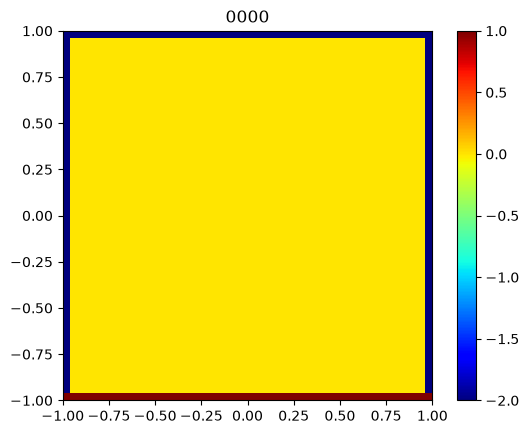

In [6]:
dlaPlot(0,matrix,path='.',name='test1',plot=True)

Literature:

- [Physics today](https://web.archive.org/web/20070405094836/http://aip.org/pt/vol-53/iss-11/p36.html)

----